# Simplification during level-up

> **In short.**
> * **The setting.** A program is built from stages; *level-up* groups them into bigger blocks, level after level (a round of checks, then a logical gate made of several rounds, then the whole protocol). Each block has a ZX-diagram.
> * **The idea (L. Yeh's suggestion).** Simplify while grouping: each block can carry a *rewrite* (such as `'gpf'`, the library's reduction, or PyZX's `'full_reduce'`), and a bigger block is built from its children's simplified diagrams. Small pieces are simplified first, then combined.
> * **The answer.** Simplifying the fold-transversal Hadamard block by block gives the same result as simplifying it at once: a Hadamard followed by a correction that depends on the measurement results (the *Pauli frame*); written modulo the detectors, the two frames are identical. For d = 3 cultivation the detectors found block by block span the same space as those found at once.
> * **How to read the pictures.** On the left of the window, the program with its blocks shaded (time left to right, one line per qubit); in the middle, the program with each block replaced by its simplified diagram; on the right, one block's simplified diagram. Green and red dots are Z- and X-spiders; a name like `c[5]` in a phase is a measurement result.
> * New to codes and ZX-diagrams? Start with [TInjectionWalkthrough.ipynb](TInjectionWalkthrough.ipynb), Part A.

A level-up groups blocks of a program into a bigger block. By default that is all it does: every analysis cuts the block's diagram out of the master graph. A level-up can also **rewrite** the block it makes: `level_up(..., rewrite='gpf')`, or `'full_reduce'`, `'clifford_simp'`, `'teleport_reduce'`, `'spider_simp'`, `'gpf-no-gadgets'`, or any function registered with `register_rewrite`.

The rewritten diagram is built from the children: each child's diagram, rewritten if the child has a rewrite of its own, glued in order along the qubit wires, and then the block's own rewrite. So small blocks are simplified first and the simplified pieces combined, level by level. `reduced_block(level, index)` returns the result, with the detectors the rewrites removed (it equals the cut diagram, up to a scalar, on the outcomes that satisfy them), spider counts and times.

The rewritten diagrams are a view. The three questions (`code_at`, `logical_action`, `summary`) are still answered from the cut diagrams, so adding rewrites changes none of their answers.

In [1]:
import pyzx as zx
from zxqec.qprogram import program_from_stim
from zxqec.gpf import reduce_gpf, detector_rank, phases_modulo
from zxqec.spacetime import draw_level_3d, view_levels, view_levels_3d
import interactive_fold_h_3d as fth          # picks a window backend when imported ...
%matplotlib inline

## The fold-transversal Hadamard, block by block

The stages are grouped into the six blocks of the paper, each with a rewrite (the fifth entry of a group; `None` only groups):

In [2]:
p = fth.build_program()
level = p.group_stages([(0, 0, 'encode + round 1', 'encoder', 'gpf'), (1, 1, 'transversal H', 'logical gate'),
                        (2, 3, 'round in code 2', 'syndrome extraction', 'gpf'), (4, 4, 'rotate', 'logical gate'),
                        (5, 6, 'round in code 1', 'syndrome extraction', 'full_reduce'),
                        (7, 7, 'checks + decode', 'decoder', 'gpf')])
print(p.describe_level(level))
print()
print(p.describe_reduced(level))

Level 6 (6 blocks):
  Block 0 'encode + round 1' (encoder) <rewrite: gpf>: [encode + X checks]
  Block 1 'transversal H' (logical gate): [transversal H]
  Block 2 'round in code 2' (syndrome extraction) <rewrite: gpf>: [Z checks (code 2), X checks (code 2)]
  Block 3 'rotate' (logical gate): [rotate 90°]
  Block 4 'round in code 1' (syndrome extraction) <rewrite: full_reduce>: [Z checks, X checks]
  Block 5 'checks + decode' (decoder) <rewrite: gpf>: [Z checks + decode]

Level 6 (6 blocks), rewritten:
  Block 0: encode + round 1 (1 children): 71 spiders -> 23 after rewrite gpf
  Block 1: transversal H (1 children): 9 spiders -> 9 after no rewrite
  Block 2: round in code 2 (2 children): 72 spiders -> 28 after rewrite gpf
  Block 3: rotate (1 children): 10 spiders -> 10 after no rewrite
  Block 4: round in code 1 (2 children): 80 spiders -> 24 after rewrite full_reduce
  Block 5: checks + decode (1 children): 69 spiders -> 15 after rewrite gpf


Levelling the six blocks up into one, rewritten by `'gpf'`: the six rewritten blocks (109 spiders) are glued and reduced. The result is the paper's: a Hadamard followed by a Pauli frame, two spiders, and 24 detectors.

whole program (6 children): 109 spiders -> 2 after rewrite gpf; 24 detector(s) removed here
made from: ['encode + round 1', 'transversal H', 'round in code 2', 'rotate', 'round in code 1', 'checks + decode']
detectors removed on the way: 24 | independent: 24


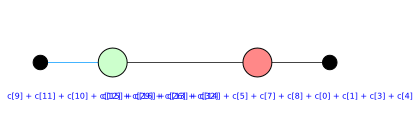

In [3]:
whole = p.level_up(level, 0, 5, 'whole program', rewrite='gpf')
rb = p.reduced_block(whole, 0)
print(rb)
print("made from:", [str(c.block) for c in rb.children])
print("detectors removed on the way:", len(rb.detectors), "| independent:", detector_rank(list(rb.detectors)))
zx.draw_matplotlib(rb.graph, figsize=(6, 2))

The two spiders carry the Pauli frame, a parity of outcomes. Here it is written with more outcomes than reducing the whole program at once gives (`c[0] + c[1] + c[2] + c[3] + c[4]` and `c[26] + c[29] + c[32]`): the blocks were reduced first, and the parities they passed up carry some detector parities, which are 0 in every run. So the two are the same frame, written two ways. `phases_modulo` writes a phase modulo the detectors, in the earliest outcomes possible, and then the two agree exactly. The window below draws every rewritten block this way.

level by level  as reduced:       ['c[15] + c[16] + c[13] + c[14] + c[5] + c[7] + c[8] + c[0] + c[1] + c[3] + c[4]', 'c[9] + c[11] + c[10] + c[12] + c[29] + c[26] + c[32]']
                modulo detectors: ['c[0] + c[1] + c[2] + c[3] + c[4]', 'c[26] + c[29] + c[32]']
at once         as reduced:       ['c[4] + c[0] + c[3] + c[1] + c[2]', 'c[29] + c[26] + c[32]']
                modulo detectors: ['c[0] + c[1] + c[2] + c[3] + c[4]', 'c[26] + c[29] + c[32]']


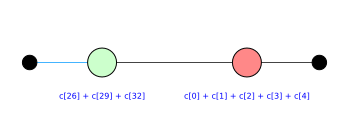

In [4]:
direct = reduce_gpf(p.quantum_graph())
for name, g, dets in (("level by level", rb.graph, rb.detectors), ("at once", direct.graph, direct.detectors)):
    print("{:15} as reduced:      ".format(name), [str(g.phase(v)) for v in g.vertices() if g.type(v) != zx.VertexType.BOUNDARY])
    h = phases_modulo(g, dets)
    print("{:15} modulo detectors:".format(""), [str(h.phase(v)) for v in h.vertices() if h.type(v) != zx.VertexType.BOUNDARY])
zx.draw_matplotlib(phases_modulo(rb.graph, rb.detectors), figsize=(6, 2))

## The same block under different rewrites

Which rewrite a block gets is a choice: the round of checks in code 1, rewritten five ways.

In [5]:
for rewrite in ('spider_simp', 'teleport_reduce', 'clifford_simp', 'full_reduce', 'gpf'):
    q = fth.build_program()
    lv = q.group_stages([(5, 6, 'round in code 1', 'syndrome extraction', rewrite)])
    index = next(k for k, b in enumerate(q.levels.blocks(lv)) if b.name == 'round in code 1')
    r = q.reduced_block(lv, index)
    print("{:16} {:3} spiders -> {:3}   detectors removed: {}".format(rewrite, r.spiders_before, r.spiders_after,
                                                                    len(r.new_detectors)))

spider_simp       80 spiders ->  46   detectors removed: 0
teleport_reduce   80 spiders ->  80   detectors removed: 0
clifford_simp     80 spiders ->  34   detectors removed: 0
full_reduce       80 spiders ->  24   detectors removed: 0
gpf               80 spiders ->  28   detectors removed: 0


## d = 3 cultivation, level by level

Each of the four blocks reduced by `'gpf'`, then the four reduced blocks glued and reduced again. The detectors removed on the way span the same space as those of reducing the whole circuit at once, and the same 13 spiders are left, with the one T† gadget.

In [6]:
c = program_from_stim(open('circuits/cultivation/d3_cultivation.stim').read())[0]
lv = c.group_stages([(0, 0, 'first checks', 'state preparation', 'gpf'), (1, 1, 'inject T', 'injection', 'gpf'),
                     (2, 2, 'checks', 'syndrome extraction', 'gpf'), (3, 4, 'double-check', 'cultivation', 'gpf')])
top = c.level_up(lv, 0, 3, 'whole program', rewrite='gpf')
print(c.describe_reduced(lv))
print(c.describe_reduced(top))
found = list(c.reduced_block(top, 0).detectors)
direct = reduce_gpf(c.quantum_graph()).detectors
print("independent detectors: level by level", detector_rank(found), "| at once", detector_rank(direct),
      "| the same span:", detector_rank(found + list(direct)) == detector_rank(found) == detector_rank(direct))

Level 4 (4 blocks), rewritten:
  Block 0: first checks (1 children): 90 spiders -> 14 after rewrite gpf; 4 detector(s) removed here
  Block 1: inject T (1 children): 97 spiders -> 25 after rewrite gpf; 5 detector(s) removed here
  Block 2: checks (1 children): 84 spiders -> 22 after rewrite gpf
  Block 3: double-check (2 children): 99 spiders -> 45 after rewrite gpf; 6 detector(s) removed here
Level 5 (1 blocks), rewritten:
  Block 0: whole program (4 children): 106 spiders -> 13 after rewrite gpf; 13 detector(s) removed here


independent detectors: level by level 28 | at once 28 | the same span: True


## The window

`view_levels(program)` opens a window: on the left the program with the blocks of a level shaded, the selected block outlined and the blocks it was made from dashed; in the middle the whole program as that level rewrites it (`reduced_level`: every block of the level replaced by its rewritten diagram, glued in order, each block's part shaded in its colour); on the right the selected block's diagram after its rewrite (or, with *plain diagram* ticked, as cut out of the circuit); below, what the block is and where it came from. The slider moves between levels, the buttons between blocks, and going down a level keeps the focus on the same stages. From a terminal, `python examples/interactive_levels.py` opens it (`--cultivation` for d = 3 cultivation). In this notebook it is shown as it starts, and moved from code:

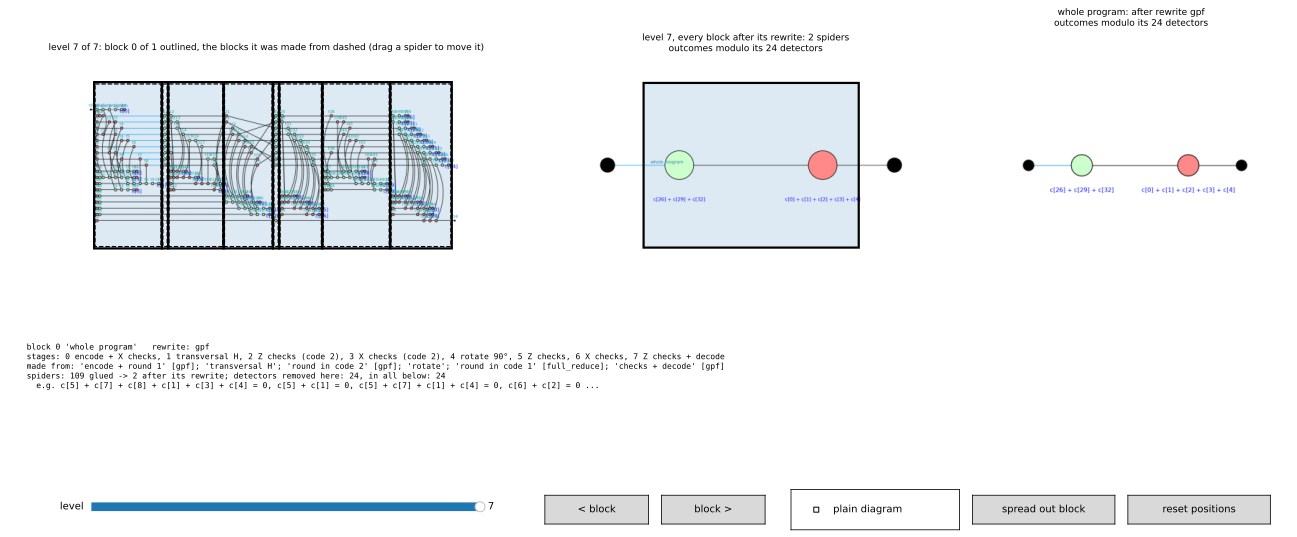

In [7]:
fig = view_levels(p)                 # the notebook shows the new figure by itself

block 4 'round in code 1' (syndrome extraction)   rewrite: full_reduce
stages: 5 Z checks, 6 X checks
made from: 'Z checks'; 'X checks'
spiders: 80 glued -> 24 after its rewrite; detectors removed here: 0, in all below: 0


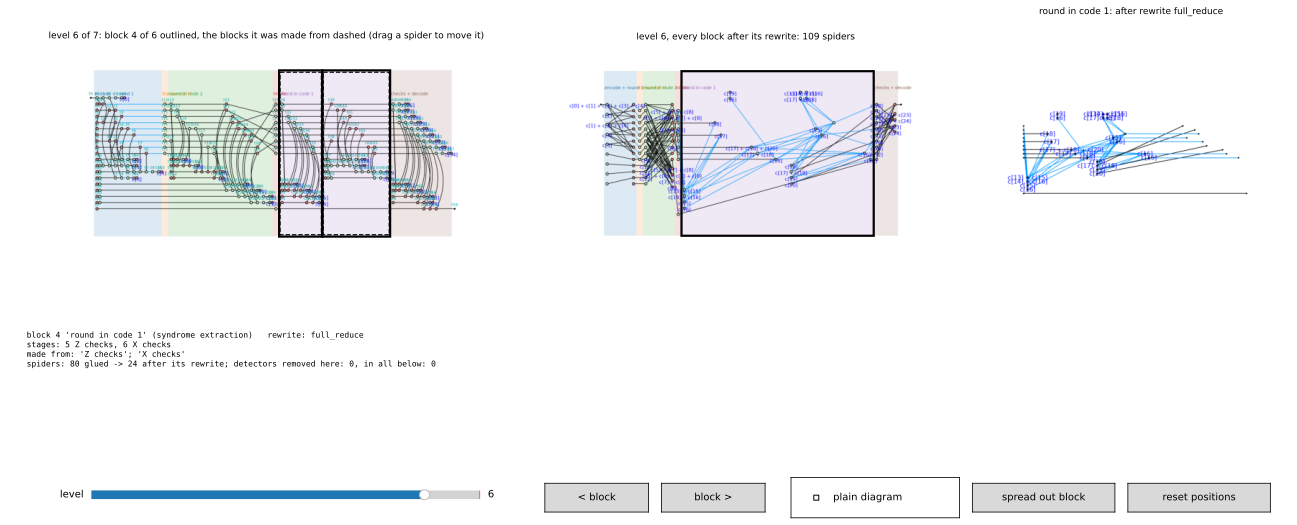

In [8]:
view = fig.levels_view
view.set_level(view.level - 1)       # one level down: the six blocks
view.set_block(4)                    # the round in code 1
print(view.describe())
fig

Labels can overlap, as in this block after `'full_reduce'`: one round alone has no detectors (its outcomes are random until compared with another round), so nothing shortens its parities, and `full_reduce` leaves sums of outcomes on its 24 spiders. In the window, drag a spider to move it: the picture is drawn again by the same function with the spider in its new place (in a copy of the graph; the program itself does not change). A move in the program picture holds on every level; a move in a block picture belongs to that block. *spread out block* lays the block out with PyZX's force-directed layout (`auto_layout_vertex_locs`), and *reset positions* undoes all moves. A notebook with the inline backend shows still pictures, so here the same is done from code:

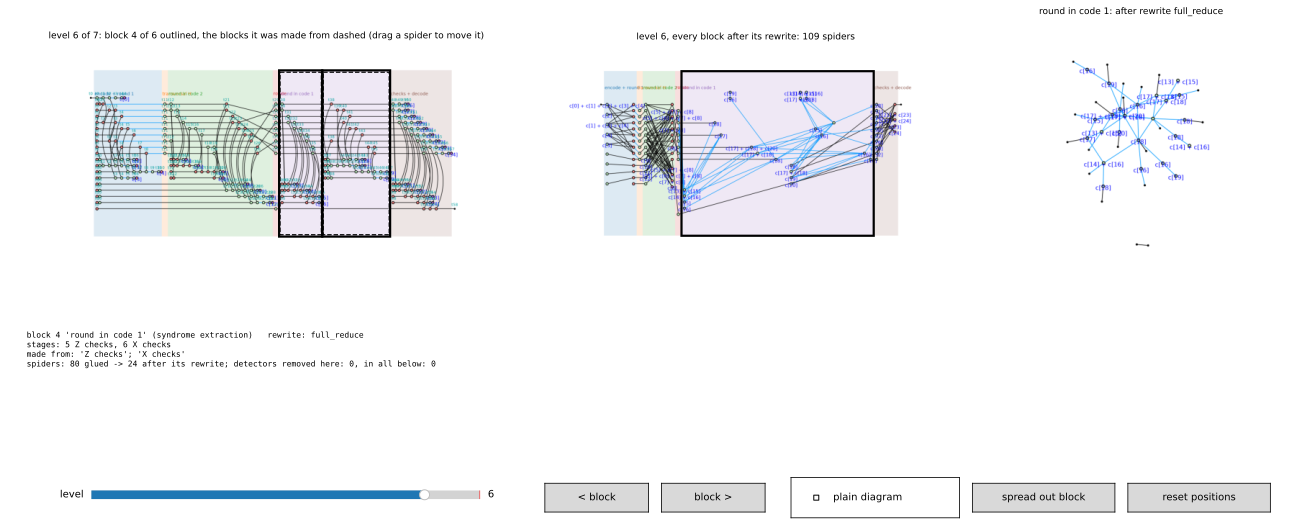

In [9]:
view.spread_block()                  # what the button does
fig

In [10]:
view.reset_positions()
print(view.block_moves, view.program_moves)

{} {}


## The program as a level rewrites it

`reduced_level(level)` is the middle picture of the window: the blocks of a level, each after its rewrites, glued in order. For example, level up only the two stages of the round in code 2, with `'gpf'`: the new level is the circuit with that round replaced by its normal form, and every other stage as it was. It equals the circuit on every run its detectors allow (`tests/test_rewrites.py` checks this on a small program).

Level 1 (7 blocks):
  Block 0 'encode + X checks': [encode + X checks]
  Block 1 'transversal H': [transversal H]
  Block 2 'round in code 2' <rewrite: gpf>: [Z checks (code 2), X checks (code 2)]
  Block 3 'rotate 90°': [rotate 90°]
  Block 4 'Z checks': [Z checks]
  Block 5 'X checks': [X checks]
  Block 6 'Z checks + decode': [Z checks + decode]
level 0: 8 blocks glued, 311 spiders; 0 detector(s) removed
level 1: 7 blocks glued, 267 spiders; 0 detector(s) removed


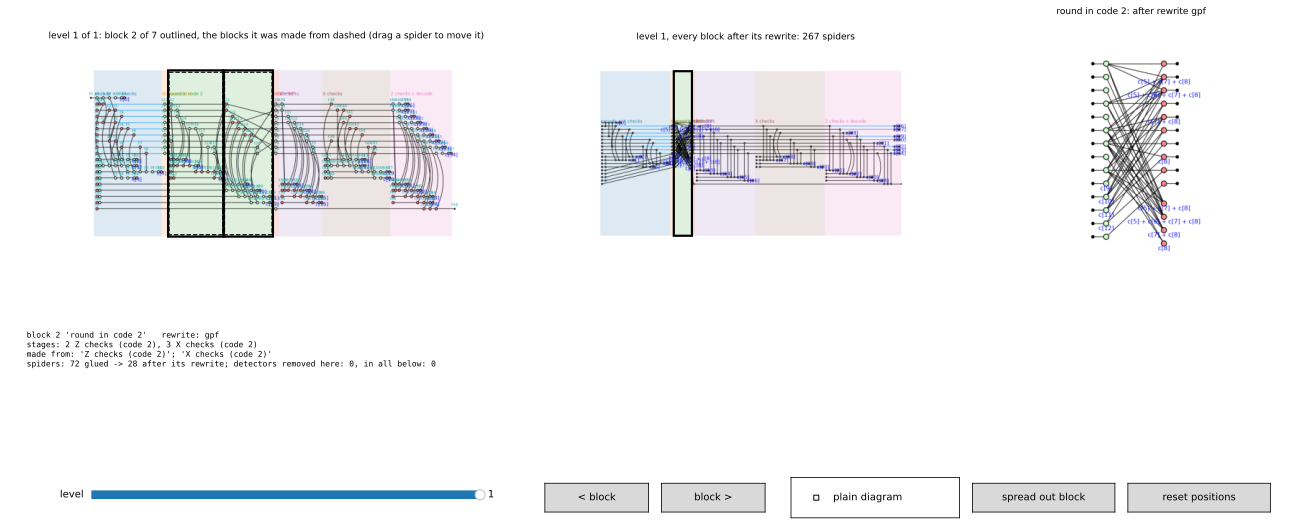

In [11]:
q = fth.build_program()
lv = q.level_up(0, 2, 3, 'round in code 2', rewrite='gpf')
print(q.describe_level(lv))
print(q.reduced_level(0))            # the circuit
print(q.reduced_level(lv))           # the same with the round in its normal form
fig_q = view_levels(q, lv, 2)

## The window in 3D

`view_levels_3d(program)` is the same window in 3D: the hardware layout flat, time upwards, the blocks of the level as slabs.

* **Left**, the program as `draw_program_3d` draws it, the selected block outlined in bold and the blocks it was made from dashed.
* **Middle**, the program as the level rewrites it, also in 3D (`draw_level_3d`), turning together with the program. What has a place in space-time is drawn there: a block without a rewrite is where it is in the circuit. A rewritten diagram has no such place, so inside a rewritten block only the ends of its wires are fixed (each where the wire enters or leaves the block), and every spider is laid out by its distances in the diagram to those ends (`level_layout_3d`): over the wire ends nearest to it, at a height dividing the block in the ratio of its distances to the inputs and to the outputs. In a normal form, the Z-spiders next to the inputs sit low over their wires and the X-spiders next to the outputs high over theirs. These positions are a layout, not a claim about where or when anything happens.
* **Right**, a rewritten block as PyZX's drawing, with spiders to drag; a block cut out of the program (*plain diagram*, or a block without a rewrite) in 3D.

In a window, drag a 3D picture to turn it, or use the buttons below it for the named viewpoints (`set_view` from code). The slider, the block buttons, the arrow keys and the other buttons work as in the flat window. From a terminal, `python examples/interactive_levels.py --3d` opens it.

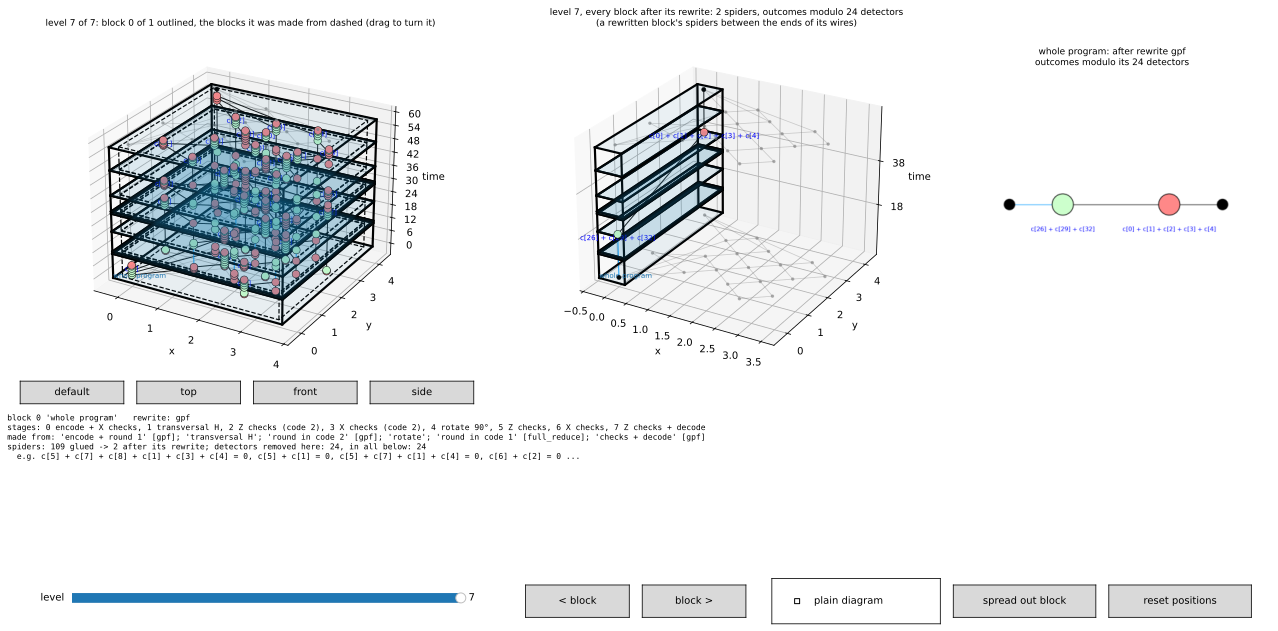

In [12]:
fig3 = view_levels_3d(p)             # the notebook shows the new figure by itself

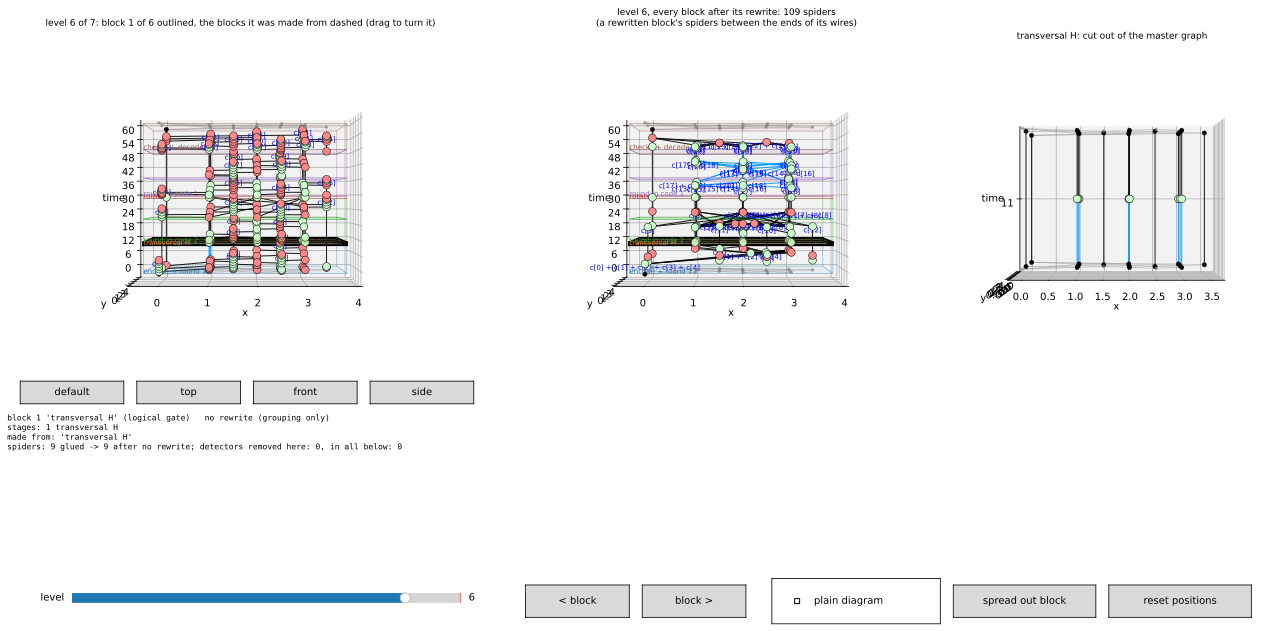

In [13]:
view3 = fig3.levels_view
view3.set_level(view3.level - 1)     # the six blocks
view3.set_block(1)                   # the transversal H: no rewrite, so cut out and drawn in 3D
view3.set_view('front')              # every 3D picture from the front
fig3

The middle picture on its own, for the program above where only the round in code 2 was levelled up with `'gpf'`: the circuit in place, and the round's normal form inside its slab, from the front.

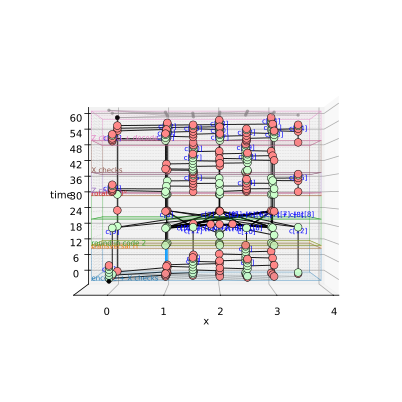

In [14]:
draw_level_3d(q, lv, figsize=(8, 7), view='front')

## What this is not

* **Not a change to the answers.** `code_at`, `logical_action` and `summary` use the cut diagrams; rewrites only add the rewritten view.
* **Rewrites are trusted to keep the map.** The built-in ones do, up to a scalar and on the outcomes the reported detectors allow (`tests/test_rewrites.py` checks each against the cut diagram, run by run, on a small program); a registered one must too.
* **PyZX's rewrites keep positions, not layouts.** A diagram after `'full_reduce'` is drawn where its spiders were; one after `'gpf'` is laid out by `layout_gpf`.